# Tutorial 1. A battery energy storage container: the electrical and thermal day

![A battery energy storage container](../tutorials/images/t01_hero.png)

**Scope:** energy storage. **Components:** `Battery`, `CurrentSource`, `Ground`,
`Convection`, `ThermalMass`, `HeatSource`, `ThermalResistance`, `Ambient`.

## The asset

A 2 MWh lithium iron phosphate container at a solar park. The racks sit in a
40-foot box with an HVAC unit on the roof. The power conversion system (PCS)
charges it through the middle of the day and discharges it into the evening
peak. Two questions decide whether the asset earns its contract:

- **State of charge and voltage.** Does the dispatch schedule stay inside the
  voltage window of the pack, and how much energy comes back out?
- **Temperature.** The cells heat by I²R losses. The HVAC has to remove that heat
  on a 30 °C day without the cell temperature climbing past 35 °C, where ageing
  accelerates.

![Process diagram](../tutorials/images/t01_pd.png)

The diagram has two circuits. On the left the electrical loop: the battery
(`BT-01`), its ohmic resistance and the PCS as a current source. On the right the
thermal network: the cell mass, convection to the container air, the HVAC
extracting heat, and the losses through the walls to ambient. The I²R losses are
the link between the two.

## Step 1. Build the battery

`Battery` is an equivalent circuit: an open-circuit voltage that depends on the
state of charge, a series resistance, one RC pair for the slow polarisation, and
a thermal mass that the losses warm. You give the data-sheet numbers; the
compiler writes the equations. The pack here is 240 LFP cells in series, so the
open-circuit curve is the cell curve times 240.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.battery import Battery
from otwin.components.electrical import CurrentSource, Ground
from otwin.components.thermal import (
    Ambient,
    Convection,
    HeatSource,
    ThermalMass,
    ThermalResistance,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

N_CELLS = 240
cell_ocv = [
    (0.0, 2.90),
    (0.05, 3.15),
    (0.20, 3.25),
    (0.50, 3.29),
    (0.80, 3.33),
    (0.95, 3.40),
    (1.0, 3.55),
]
pack = Battery(
    capacity=2600.0,  # Ah: 2600 Ah x 768 V = 2.0 MWh
    ocv=[(soc, v * N_CELLS) for soc, v in cell_ocv],  # V, the pack curve
    resistance=0.012,  # ohm, ohmic part of the pack
    rc_branches=[(0.008, 4000.0)],  # (ohm, F): a 32 s polarisation
    thermal=1.5e7,  # J/K: 15 t of cells
    soc=0.35,
    temperature=298.15,
    name="pack",
)
pcs = CurrentSource(None, name="pcs")  # A, an input: + discharges
gnd = Ground(name="gnd")
print(pack, "\nports:", list(pack.ports))

Battery(pack) 
ports: ['p', 'n', 'thermal']


The battery exposes three ports: the electrical pair `p`, `n` and a `thermal`
port at the cell temperature. Everything else, the five internal elements and the
three states, is the component's business.

## Step 2. Add the container's thermal network

Heat leaves the cells by convection to the container air (the racks are fan
cooled, so the coefficient is high), the HVAC extracts heat from the air, and the
walls leak a little to the outside.

In [ ]:
air = ThermalMass(
    1.0e6, temperature=298.15, name="air"
)  # J/K: the air, the cabinets, the floor
racks_to_air = Convection(
    4000.0, name="racks_to_air"
)  # W/K, forced convection over the modules
hvac = HeatSource(None, name="hvac")  # W, an input: negative removes heat
walls = ThermalResistance(1 / 60.0, name="walls")  # K/W: 60 W/K through the envelope
outside = Ambient(303.15, name="outside")  # a 30 degC day

system = gnd >> pack >> pcs >> gnd  # the electrical loop
system.connect(pack.thermal, racks_to_air.a)
system.connect(racks_to_air.b, air.port, hvac.port, walls.a)
system.connect(walls.b, outside.port)
model = otwin.compile(system, dt=60.0)
print(model.summary())

System: system

Components:
  gnd                          ground [any]
  pack.ocv                     open_circuit [electrical]
  pack.r0                      resistor [electrical]
  pack.r1                      resistor [electrical]
  pack.c1                      capacitor [electrical]
  pack.cell                    thermal_mass [thermal]
  pack.losses                  losses [thermal]
  pcs                          current_source [electrical]
  racks_to_air                 convection [thermal]
  air                          thermal_mass [thermal]
  hvac                         heat_source [thermal]
  walls                        thermal_resistance [thermal]
  outside                      ambient [thermal]

States:
  pack.ocv.charge              charge [C]  x0 = 3.276e+06
  pack.c1.charge               charge [C]  x0 = 0
  pack.cell.heat               stored heat [J]  x0 = 4.47225e+09
  air.heat                     stored heat [J]  x0 = 2.9815e+08

Inputs:
  pcs                      

The summary lists four states: the battery's charge, the charge of its RC pair,
the heat stored in the cells, and the heat stored in the container air. Two
inputs: the PCS current and the HVAC heat. The representation is
`pseudo-port-hamiltonian`, which is the compiler saying that temperature times
heat flow is not a power, so the energy audit on the thermal part is a stability
statement, while the heat balance itself is exact.

## Step 3. A day of dispatch

The PCS charges at 0.25 C from 10:00 to 12:30 (1625 Ah, 0.625 of the capacity)
and discharges the same charge at 0.5 C from 18:00 to 19:15. The HVAC is a
proportional controller computed here in Python: it removes 30 kW per kelvin of
air temperature above 25 °C, up to 60 kW. Because the HVAC decision depends on the
state, the input is a function of time and state, which `simulate` accepts.

In [ ]:
t = np.arange(0, 24 * 3600 + 1, 60.0)
hours = t / 3600


def dispatch(time):
    h = (time / 3600) % 24
    if 10 <= h < 12.5:
        return -650.0  # A, charging at 0.25 C
    if 18 <= h < 19.25:
        return 1300.0  # A, discharging at 0.5 C
    return 0.0


def hvac_control(time, x):
    air_temperature = x[model.state_names.index("air.heat")] / 1.0e6
    return -min(60_000.0, max(0.0, 30_000.0 * (air_temperature - 298.15)))  # W removed


run = model.simulate(t=t, inputs={"pcs": dispatch, "hvac": hvac_control})
energy_out = np.trapezoid(np.maximum(run["pcs"], 0) * run["pack.voltage"], t) / 3.6e6
energy_in = -np.trapezoid(np.minimum(run["pcs"], 0) * run["pack.voltage"], t) / 3.6e6
print(
    f"state of charge: start {run['pack.soc'][0]:.2f}, after charging {run['pack.soc'][hours.searchsorted(12.5)]:.2f}, "
    f"end of day {run['pack.soc'][-1]:.2f}"
)
print(
    f"voltage window: {run['pack.voltage'].min():.0f} to {run['pack.voltage'].max():.0f} V"
)
print(
    f"energy in {energy_in:.0f} kWh, energy out {energy_out:.0f} kWh, round-trip {energy_out / energy_in:.1%} of the charge returned"
)
print(
    f"cell temperature: max {run['pack.temperature'].max() - 273.15:.1f} degC; air max {(run['air.heat'] / 1.0e6).max() - 273.15:.1f} degC"
)
print(
    f"HVAC: {np.trapezoid(-run['hvac'], t) / 3.6e6:.0f} kWh removed, peak {-run['hvac'].min() / 1e3:.0f} kW"
)

state of charge: start 0.35, after charging 0.98, end of day 0.35
voltage window: 759 to 844 V
energy in 1316 kWh, energy out 1254 kWh, round-trip 95.3% of the charge returned
cell temperature: max 31.3 degC; air max 25.7 degC
HVAC: 70 kWh removed, peak 22 kW


Read the results together. The state of charge goes from 0.35 to near the top of
the window and back, so the day is one full cycle of the usable range. The
voltage stays inside the pack window. The energy returned over the energy stored
is the day's round-trip figure; the difference is the I²R loss, which is exactly
the heat the thermal side receives. The cells warm during the power phases and
stay under the ageing threshold; the HVAC removes the energy printed, which is
the day's loss less what the walls let in. A charge of 0.25 C for 2.5 hours is 0.625 of the capacity: the battery
component does not clamp the state of charge, so a dispatch that overfills the
pack shows up as a state of charge above one, which is the model telling you
the schedule is wrong.

## Step 4. Plot the day

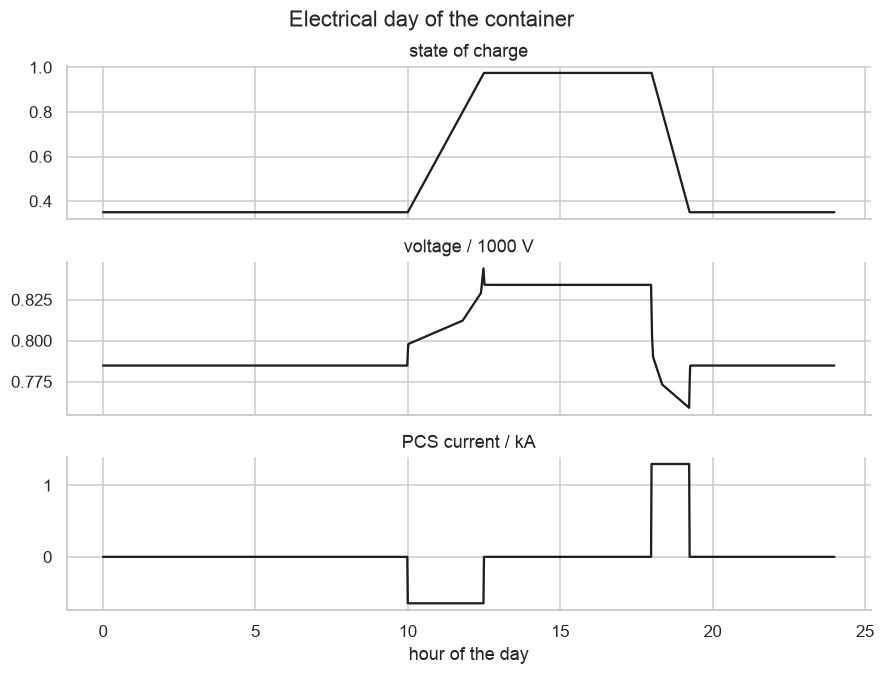

In [ ]:
frame = pd.DataFrame(
    {
        "hour": hours,
        "state of charge": run["pack.soc"],
        "voltage / 1000 V": run["pack.voltage"] / 1000,
        "PCS current / kA": run["pcs"] / 1000,
    }
)
long = frame.melt("hour", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="hour",
    y="value",
    row="signal",
    kind="line",
    height=2.0,
    aspect=4.2,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.set_axis_labels("hour of the day", "")
g.figure.suptitle("Electrical day of the container", y=1.02)

The top panel is the state of charge rising through the solar hours and falling
in the evening. The middle panel is the terminal voltage: it steps up when the
charge current starts (the ohmic drop) and relaxes over about half a minute (the
RC pair), then follows the open-circuit curve. The bottom panel is the dispatch.

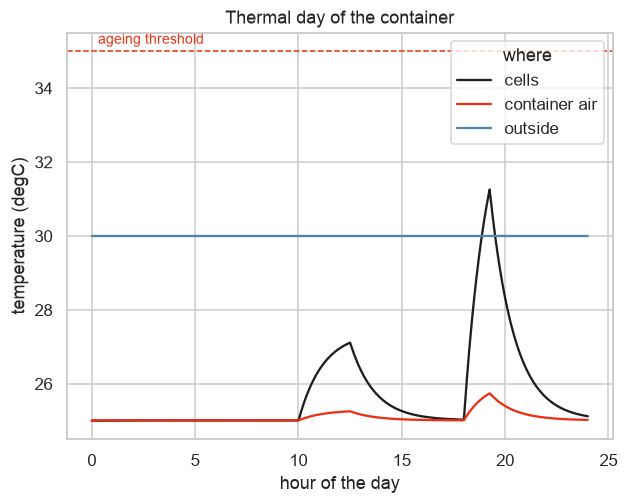

In [ ]:
thermal = pd.DataFrame(
    {
        "hour": hours,
        "cells": run["pack.temperature"] - 273.15,
        "container air": run["air.heat"] / 1.0e6 - 273.15,
        "outside": np.full(t.size, 30.0),
    }
).melt("hour", var_name="where", value_name="temperature (degC)")
ax = sns.lineplot(data=thermal, x="hour", y="temperature (degC)", hue="where")
ax.axhline(35, color="#EC3013", ls="--", lw=1)
ax.text(0.3, 35.2, "ageing threshold", color="#EC3013", fontsize=9)
ax.set_title("Thermal day of the container")
ax.set_xlabel("hour of the day")

The cells warm during the charge, more steeply during the 0.5 C discharge (the
loss goes with the square of the current), and the air follows with a lag set by
its heat capacity, held near 25 °C by the controller. Whenever the cells
approach the threshold the heat flows are what to look at next: `run["pack.heat_flow"]` is the I²R generation, `run["racks_to_air.heat_flow"]`
what convection carries away, `run["walls.heat_flow"]` what leaks in from a hot day.

## What to take from this

- A device component (`Battery`) hides its equations and exposes ports, so the
  electrical and thermal sides are joined with two `connect` calls.
- Losses cross domains without any extra wiring: the battery's I²R becomes heat at
  its `thermal` port.
- Inputs can be schedules (a function of time) or feedback (a function of time and
  state), so an HVAC controller is three lines of Python.

Next: [Tutorial 2](02_dc_distribution_feeder.md) connects a feeder like this one
to its loads.